In [1]:
import proteosim_JKa as ps
from proteosim_JKa import file_handling


In [2]:
with open(ps.__file__) as f:
    print(f.read())

from .file_handling import read_fasta

from .protein_digestion import (
       enzyme_cleavage_patterns,
       digest_protein_sequence,
       digest_protein_collection,
       compute_sequence_coverage,
   )

from .liquid_chromatography import(
        predict_lc_retention_times,
        plot_retention_time,
        select_retention_time_window
    )


import numpy as np
import matplotlib.pyplot as plt

from .mass_spectra_simulation import(
    amino_acid_mass_dalton,
    calculate_mol_mass,
    calculate_mol_mass_collection,
    calculate_mz_collection,
    plot_spectrum,
    fragment_peptide
)


In [3]:
# file_handling.read_fasta("C:\AdvancedPythonBludau\Musterkurs\data\sample_proteins.fasta")

proteins = ps.read_fasta("../data/sample_proteins.fasta")
len(proteins)

P11802: 303
A0A087WTH1: 116
A0A087WTH5: 138


3

In [4]:
digested_proteins = ps.digest_protein_collection(proteins, '(?<=[KR])(?!P)', max_pep_len= 100)

digestion_coverage = ps.compute_sequence_coverage(peptides=digested_proteins['P11802'], protein_seq= proteins['P11802'])

print(digestion_coverage)

92.73927392739274


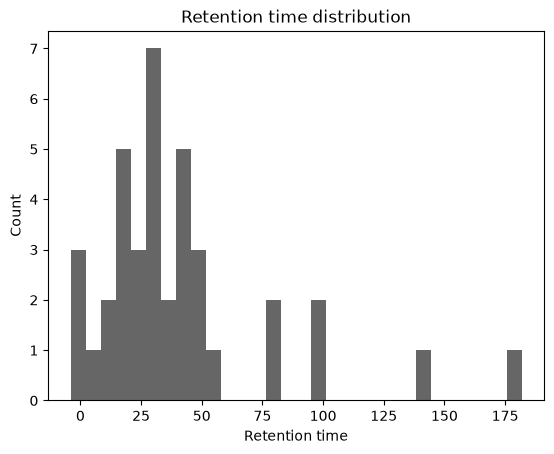

In [8]:
pooled_peptides = []
for peptide_list in digested_proteins.values():
    for item in peptide_list:
        pooled_peptides.append(item)

retention_times = ps.predict_lc_retention_times(pooled_peptides)

plot_retention_times = ps.plot_retention_time(retention_times)

filtered_retention_times = ps.select_retention_time_window(retention_times, lower_ret_time= 0, upper_ret_time=50)

In [10]:
print(filtered_retention_times)

{'MATSR': 8.9, 'YEPVAEIGVGAYGTVYK': 42.7, 'DPHSGHFVALK': 29.0, 'VPNGGGGGGGLPISTVR': 31.6, 'EVALLR': 25.5, 'LEAFEHPNVVR': 33.5, 'LMDVCATSR': 23.6, 'VTLVFEHVDQDLR': 41.0, 'TYLDK': 11.1, 'APPPGLPAETIK': 29.1, 'GLDFLHANCIVHR': 47.5, 'DLKPENILVTSGGTVK': 34.5, 'LADFGLAR': 29.5, 'KPLFCGNSEADQLGK': 28.0, 'DVSLPR': 14.7, 'GAFPPR': 16.3, 'ISAFR': 19.9, 'ALQHSYLHK': 28.5, 'AVEILGNTEAAHPPSPIR': 43.8, 'CCWLR': 24.6, 'SEEAVR': 5.7, 'MVIEWERPR': 30.9, 'LWQETVQQGGNMSGLAR': 39.4, 'LEHSNDPFNVYIESNAWQEK': 42.6, 'AYVQAR': 15.6, 'VLESYR': 18.4}


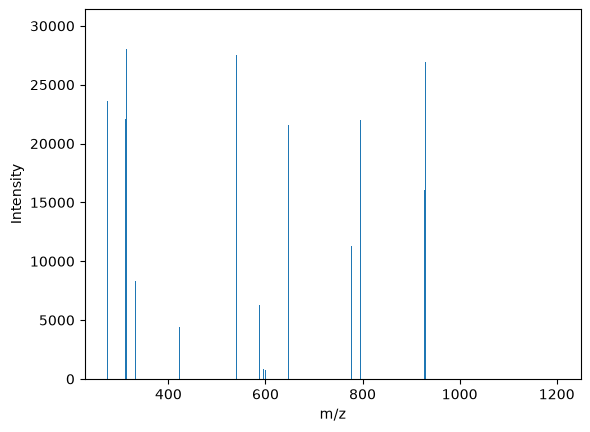

In [17]:
# calculated_molecular_mass = ps.calculate_mol_mass(filtered_retention_times[], ps.amino_acid_mass_dalton)

calculated_molecular_masses = ps.calculate_mol_mass_collection(filtered_retention_times, ps.amino_acid_mass_dalton)

calculated_mz_mass_dict = ps.calculate_mz_collection(calculated_molecular_masses, charge = 2)

spectrum_plot = ps.plot_spectrum(calculated_mz_mass_dict)

fragmented_peptides = {}

for peptide in calculated_mz_mass_dict:
    fragmented_peptides[peptide] = ps.fragment_peptide(peptide)

In [16]:
print(calculated_mz_mass_dict)

{'MATSR': {'mz': 274.332, 'mass': 546.65}, 'YEPVAEIGVGAYGTVYK': {'mz': 900.0269999999998, 'mass': 1798.0399999999997}, 'DPHSGHFVALK': {'mz': 595.677, 'mass': 1189.3400000000001}, 'VPNGGGGGGGLPISTVR': {'mz': 739.3319999999998, 'mass': 1476.6499999999996}, 'EVALLR': {'mz': 341.92699999999996, 'mass': 681.8399999999999}, 'LEAFEHPNVVR': {'mz': 647.2420000000001, 'mass': 1292.4700000000003}, 'LMDVCATSR': {'mz': 489.59700000000004, 'mass': 977.1800000000001}, 'VTLVFEHVDQDLR': {'mz': 777.3870000000001, 'mass': 1552.7600000000002}, 'TYLDK': {'mz': 311.362, 'mass': 620.71}, 'APPPGLPAETIK': {'mz': 587.212, 'mass': 1172.41}, 'GLDFLHANCIVHR': {'mz': 739.372, 'mass': 1476.73}, 'DLKPENILVTSGGTVK': {'mz': 827.4619999999999, 'mass': 1652.9099999999999}, 'LADFGLAR': {'mz': 423.002, 'mass': 843.99}, 'KPLFCGNSEADQLGK': {'mz': 795.4119999999999, 'mass': 1588.81}, 'DVSLPR': {'mz': 334.892, 'mass': 667.77}, 'GAFPPR': {'mz': 313.877, 'mass': 625.74}, 'ISAFR': {'mz': 288.35200000000003, 'mass': 574.69}, 'ALQH